In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae
import json
ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))

In [3]:
# -- Indices to plot (largest + 3 in the middle) ------------------------------
ch_idx_by_test = {
    5:  [3, 6, 8, 11],   # j ≈ 756,  1988, 3000, 4500
    16: [3, 6, 9, 11],   # j ≈ 753,  1494, 2506, 3494
    25: [3, 6, 9, 11],   # j ≈ 310,  810,  1500, 1994
}
dis_idx_by_test = {
    5:  [1, 3, 5, 7],    # j ≈ 500,  1000, 1523, 2023
    16: [2, 5, 9, 12],   # j ≈ 753,  1517, 2539, 4034
    25: [2, 6, 10, 13],  # j ≈ 506,  1530, 2530, 4036
}

In [4]:
import numpy as np
from pathlib import Path

ROOT = Path("../..").resolve()  # repo root, relative to notebooks/plotting

test_nos = [5, 16, 25]
data = {t: np.load(ROOT / f"results/test{t}_results.npz") for t in test_nos}

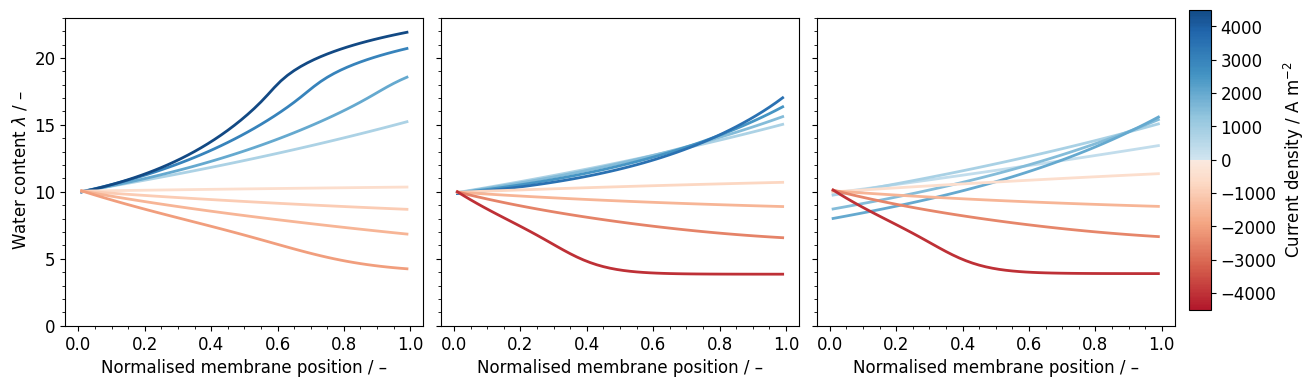

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
plt.rcParams.update({
    'font.size':        12,   # base size
    'axes.labelsize':   12,   # x/y axis labels
    'axes.titlesize':   12,   # subplot titles (if used)
    'xtick.labelsize':  12,   # x tick labels
    'ytick.labelsize':  12,   # y tick labels
    'legend.fontsize':  10,   # legend
})
# -- Colormap -----------------------------------------------------------------
rdbu = plt.cm.RdBu_r
# Red half: deep red (far from white) -> very faded red (close to white at zero)
colors_pos = rdbu(np.linspace(0.90, 0.55, 128))   # deep red -> near-white red
# Blue half: already-saturated blue (not too white at zero) -> deep blue
colors_neg = rdbu(np.linspace(0.4, 0.05, 128))   # mid-blue -> deep blue
colors = np.vstack([colors_pos, colors_neg])
cmap = LinearSegmentedColormap.from_list('RdBu_asymmetric', colors)

# -- Global norm across all three tests ---------------------------------------
all_j = []
for t in test_nos:
    d = data[t]
    all_j.append(-d['j_discharge_lam'])
    all_j.append(d['j_charge_lam'])
all_j = np.concatenate(all_j)
vabs = np.abs(all_j).max()
norm = TwoSlopeNorm(vmin=-vabs, vcenter=0, vmax=vabs)

# -- Indices to plot ----------------------------------------------------------
ch_idx_by_test = {
    5:  [3, 6, 8, 11],
    16: [3, 6, 9, 11],
    25: [3, 6, 9, 11],
}
dis_idx_by_test = {
    5:  [1, 3, 5, 7],
    16: [2, 5, 9, 12],
    25: [2, 6, 10, 13],
}

# -- Plot ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4), sharey=True)

for ax, t in zip(axes, test_nos):
    d = data[t]
    x_mem    = d['x_mem']
    lam_ch   = d['lam_ch']
    lam_dis  = d['lam_dis']
    j_charge_lam    = d['j_charge_lam']
    j_discharge_lam = d['j_discharge_lam']

    for i in ch_idx_by_test[t]:
        ax.plot(x_mem, lam_ch[i],
                color=cmap(norm(j_charge_lam[i])), lw=2)
    for i in dis_idx_by_test[t]:
        ax.plot(x_mem, lam_dis[i],
                color=cmap(norm(-j_discharge_lam[i])), lw=2)

    ax.set_xlabel('Normalised membrane position / –')
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.set_ylim(0, 23)

axes[0].set_ylabel(r' Water content $\lambda$ / –')

fig.subplots_adjust(right=0.89, wspace=0.05)
# -- Shared colorbar ----------------------------------------------------------
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.75])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label(r'Current density / A m$^{-2}$')


out_path = ROOT / f"figures/lambda_sim_all_tests.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, bbox_inches='tight')
plt.show()

## Biot number analysis (per curve)

The `test{N}_results.npz` files only store the converged $\lambda(x)$ profiles, not
the full cell state needed for the interfacial coefficients below. So for each of
the 24 selected (test, mode, $j_{appl}$) curves above, this section re-runs the DAE
to steady state (same fitted membrane/kinetic parameters used to generate those
npz files) to recover the actual converged state, then computes:

- **Effective membrane water diffusivity**:
  $D_{eff} = L_m \big/ \int (dx/D_w(\lambda(x)))$, evaluated node-by-node over the
  converged $\lambda(x)$ profile with the same diffusivity model (`hwang`) used in
  `membrane_residual`.
- **Interfacial resistance**: $R_{int} = 1/k_{ca,eff} + 1/k_{an,eff}$, with
  $k_{an,eff} = k_{vw,eff} + k_{lw,eff}$ — the exact volume-fraction-corrected,
  sorption/desorption-blended coefficients computed inline in
  `dae_residual_full_cell.py` (lines ~392-423), evaluated at the converged boundary
  water contents $\lambda(0)$, $\lambda(L_m)$ and anode ACL saturation $s$.
- **Biot number**: $Bi = (L_m/D_{eff}) / R_{int}$ — ratio of the membrane's internal
  diffusive resistance to the combined cathode+anode interfacial resistance.

In [26]:
import sys, json
import numpy as np
import pandas as pd
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))
from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import membraneparams, cathodeparams, anodeparams, cellparams, Vars

TF, RTOL = 1800, 1e-5


def biot_numbers(cell, y_final):
    """D_eff, interfacial k_eff's and Bi from a converged full-cell state vector."""
    cell.dae_residual_full_cell(0.0, y_final, np.zeros_like(y_final))  # refresh cell.bc

    state = cell.split_state(y_final)
    lam   = state["membrane"][:, 0]
    s_acl = state["anode"][2]   # ACL liquid saturation -- anode-side BC source

    V_w, V_m = cell.membrane.V_w, cell.membrane.V_m
    dx_m     = cell._dx_m       # physical control-volume widths [m]
    L_m      = cell.membrane.thickness

    # -- effective diffusivity, D_eff = L_m / sum(dx_i / D_w(lambda_i)) ---------
    D_w_nodes = cell.membrane_water_diffusivity(lam, "hwang")
    R_diff    = float(np.sum(dx_m / D_w_nodes))   # = L_m / D_eff   [s/m]
    D_eff     = L_m / R_diff

    # -- cathode-side interfacial coefficient, same formula as dae_residual_full_cell.py:392-404
    a_left      = cell.bc[Vars.a]["membrane"]["left"].value
    lam_eq_left = cell.return_lambda_cath_eq(a_left)
    lam_eq_left = cell.return_lambda_corr(lam_eq_left)
    k_ca        = cell.membrane.k_ca_lw
    f_v_ca      = lam[0] * V_w / (lam[0] * V_w + V_m)
    k_ca_corr   = k_ca * f_v_ca
    delta_lam   = lam[0] - lam_eq_left
    blend       = 0.5 * (1.0 + np.tanh(delta_lam / 0.1))
    k_ca_eff    = blend * k_ca_corr * 10 + (1 - blend) * k_ca_corr

    # -- anode-side interfacial coefficient, same formula as dae_residual_full_cell.py:380-391,420-423
    a_right      = cell.bc[Vars.a]["membrane"]["right"].value
    lam_eq_right = cell.return_lambda_eq(a_right)
    if lam_eq_right < 2.01:
        lam_eq_right = 2.01

    s_im    = cell.anode.s_im
    beta_sr = 100000
    s_r     = np.logaddexp(0.0, beta_sr * (s_acl - s_im)) / (beta_sr * (1 - s_im))
    f_v_an  = lam[-1] * V_w / (lam[-1] * V_w + V_m)

    k_sorp_vw   = cell.membrane.k_sorp_vw   * f_v_an * (1 - s_acl)
    k_desorp_vw = cell.membrane.k_desorp_vw * f_v_an * (1 - s_acl)
    k_sorp_lw   = cell.membrane.k_sorp_lw   * f_v_an * s_r
    k_desorp_lw = cell.membrane.k_desorp_lw * f_v_an * s_r

    delta_lam_an = lam[-1] - lam_eq_right
    blend_an     = 0.5 * (1.0 + np.tanh(delta_lam_an / 0.1))
    k_vw_eff     = blend_an * k_desorp_vw + (1 - blend_an) * k_sorp_vw
    k_lw_eff     = blend_an * k_desorp_lw + (1 - blend_an) * k_sorp_lw
    k_an_eff     = k_vw_eff + k_lw_eff

    R_int = 1.0 / k_ca_eff + 1.0 / k_an_eff
    Bi    = R_diff / R_int

    return dict(
        D_eff=D_eff, R_diff=R_diff, k_ca_eff=k_ca_eff, k_an_eff=k_an_eff,
        R_int=R_int, Bi=Bi, lam_ca=float(lam[0]), lam_an=float(lam[-1]),
    )

In [27]:
hfr_csv  = pd.read_csv(ROOT / "data" / "experimental" / "HFR.csv")
biot_rows = []

for test_no in test_nos:
    print(f"\n=== Biot analysis: test {test_no} ===")
    d = data[test_no]

    hfr_df = hfr_csv[hfr_csv["test_no"] == test_no]
    soc = hfr_df["SOC"].iloc[0]
    T   = hfr_df["T(°C)"].iloc[0]
    Q_v = hfr_df["Q_v (ml/min)"].iloc[0]

    # -- same fitted membrane/kinetic parameters used to generate test{N}_results.npz --
    fit_dir = ROOT / "results" / "test fitting" / f"test {test_no}"
    hfr_fit = sorted(fit_dir.glob(f"fit_v2_test{test_no}_*.json"))[-1]
    e_fit   = sorted(fit_dir.glob(f"fit_e_cell_test{test_no}_*.json"))[-1]

    with open(hfr_fit) as f:
        fit = json.load(f)
    p, s = fit["params"], fit["settings"]
    membraneparams.k_sorp_vw   = p["k_vw_sorp"]
    membraneparams.k_desorp_vw = p["S_desorp"] * p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = p["k_lw_sorp"]
    membraneparams.k_desorp_lw = p["S_desorp"] * p["k_lw_sorp"]
    membraneparams.k_ca_lw     = p["k_ca"]
    membraneparams.sf_D        = s["sf_D"]
    cellparams.vanadium_uptake = s["vanadium_uptake"]

    with open(e_fit) as f:
        e_params = json.load(f)["params"]
    cathodeparams.reaction_rate_constant = e_params["k_ca"]
    anodeparams.j_0                      = e_params["j0_an"]

    curves = (
        [("charge",    i, float(d["j_charge_lam"][i]))     for i in ch_idx_by_test[test_no]] +
        [("discharge", i, -float(d["j_discharge_lam"][i])) for i in dis_idx_by_test[test_no]]
    )

    for mode, idx, j_appl in curves:
        cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
        atol         = build_atol(cell)
        jac_sparsity = cell.compute_jac_sparsity(y0, yp0)
        sol = solve_dae(
            cell.dae_residual_full_cell,
            (0.0, TF), y0, yp0,
            method="BDF", atol=atol, rtol=RTOL,
            events=soc_cutoff_event, jac_sparsity=jac_sparsity,
        )
        bq = biot_numbers(cell, sol.y[:, -1])
        bq.update(test=test_no, mode=mode, idx=idx, j_appl=j_appl, soc=float(soc), success=sol.success)
        biot_rows.append(bq)

        print(f"  {mode:9s} j={j_appl:+7.0f} A/m²  success={sol.success}  "
              f"D_eff={bq['D_eff']:.3e} m²/s  k_ca_eff={bq['k_ca_eff']:.3e}  "
              f"k_an_eff={bq['k_an_eff']:.3e} m/s  R_int={bq['R_int']:.3e}  "
              f"R_diff={bq['R_diff']:.3e} s/m  Bi={bq['Bi']:.4f}")

biot_df = pd.DataFrame(biot_rows)
biot_df


=== Biot analysis: test 5 ===
  charge    j=   +756 A/m²  success=True  D_eff=1.717e-10 m²/s  k_ca_eff=2.422e-03  k_an_eff=2.734e-06 m/s  R_int=3.662e+05  R_diff=7.399e+05 s/m  Bi=2.0206
  charge    j=  +1988 A/m²  success=True  D_eff=1.731e-10 m²/s  k_ca_eff=2.332e-03  k_an_eff=3.073e-06 m/s  R_int=3.258e+05  R_diff=7.337e+05 s/m  Bi=2.2519
  charge    j=  +3000 A/m²  success=True  D_eff=2.044e-10 m²/s  k_ca_eff=2.262e-03  k_an_eff=3.282e-06 m/s  R_int=3.051e+05  R_diff=6.214e+05 s/m  Bi=2.0366
Call 20000: t=36.645983, max|res|=1.790518e-04
  charge    j=  +4500 A/m²  success=True  D_eff=2.385e-10 m²/s  k_ca_eff=2.131e-03  k_an_eff=3.506e-06 m/s  R_int=2.857e+05  R_diff=5.325e+05 s/m  Bi=1.8641
  discharge j=   -500 A/m²  success=True  D_eff=1.699e-10 m²/s  k_ca_eff=2.471e-03  k_an_eff=1.681e-06 m/s  R_int=5.954e+05  R_diff=7.476e+05 s/m  Bi=1.2557
  discharge j=  -1000 A/m²  success=True  D_eff=1.638e-10 m²/s  k_ca_eff=2.483e-03  k_an_eff=1.471e-06 m/s  R_int=6.804e+05  R_diff=7.751

,D_eff,R_diff,k_ca_eff,k_an_eff,R_int,Bi,lam_ca,lam_an,test,mode,idx,j_appl,soc,success
0,1.716550e-10,7.398559e+05,0.002422,2.734197e-06,3.661509e+05,2.020631,10.036550,15.233430,5,charge,3,755.813954,0.1,True
1,1.730907e-10,7.337194e+05,0.002332,3.073205e-06,3.258219e+05,2.251903,10.019858,18.560053,5,charge,6,1988.372093,0.1,True
2,2.043899e-10,6.213614e+05,0.002262,3.282407e-06,3.050965e+05,2.036606,10.006828,20.702218,5,charge,8,3000.000000,0.1,True
3,2.384829e-10,5.325330e+05,0.002131,3.506130e-06,2.856841e+05,1.864063,9.986817,21.913449,5,charge,11,4500.000000,0.1,True
4,1.698684e-10,7.476378e+05,0.002471,1.680746e-06,5.953787e+05,1.255735,10.052160,10.354583,5,discharge,1,-500.000000,0.1,True
5,1.638414e-10,7.751400e+05,0.002483,1.470695e-06,6.803535e+05,1.139319,10.058194,8.692877,5,discharge,3,-1000.000000,0.1,True
6,1.358555e-10,9.348167e+05,0.002492,1.214952e-06,8.234790e+05,1.135204,10.064384,6.844350,5,discharge,5,-1523.255814,0.1,True
7,6.854798e-11,1.852717e+06,0.002491,8.105869e-07,1.234075e+06,1.501299,10.069923,4.251270,5,discharge,7,-2023.255814,0.1,True
8,1.715987e-10,7.400990e+05,0.000894,1.267160e-05,8.003569e+04,9.247112,9.944860,15.037565,16,charge,3,752.808989,0.5,True
9,1.714798e-10,7.406118e+05,0.000829,1.419085e-05,7.167361e+04,10.333117,9.929957,15.612659,16,charge,6,1494.382022,0.5,True


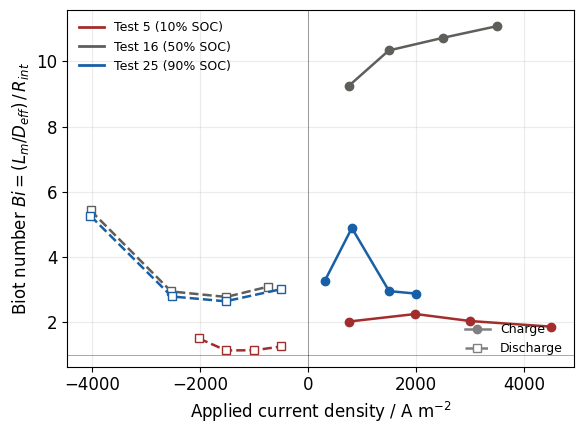

In [28]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

custom     = LinearSegmentedColormap.from_list("soc", ['#A32D2D', '#5F5E5A', '#185FA5'])
soc_colors = {t: c for t, c in zip(test_nos, custom(np.linspace(0.0, 1.0, len(test_nos))))}
test_labels = {5: "10% SOC", 16: "50% SOC", 25: "90% SOC"}

fig, ax = plt.subplots(figsize=(6, 4.5))

for test_no in test_nos:
    sub = biot_df[biot_df["test"] == test_no].sort_values("j_appl")
    c   = soc_colors[test_no]
    ch  = sub[sub["mode"] == "charge"]
    dis = sub[sub["mode"] == "discharge"]
    ax.plot(ch["j_appl"],  ch["Bi"],  "o-",  color=c, lw=1.8, ms=6)
    ax.plot(dis["j_appl"], dis["Bi"], "s--", color=c, lw=1.8, ms=6, mfc="white")

ax.axhline(1, color="k", lw=0.6, alpha=0.4)
ax.axvline(0, color="k", lw=0.6, alpha=0.4)
ax.set_xlabel(r"Applied current density / A m$^{-2}$")
ax.set_ylabel(r"Biot number $Bi = (L_m/D_{eff})\,/\,R_{int}$")
ax.grid(True, alpha=0.25)

test_handles = [Line2D([0], [0], color=soc_colors[t], lw=2, label=f"Test {t} ({test_labels[t]})")
                for t in test_nos]
style_handles = [
    Line2D([0], [0], color="gray", marker="o", lw=1.8, label="Charge"),
    Line2D([0], [0], color="gray", marker="s", lw=1.8, ls="--", mfc="white", label="Discharge"),
]
leg1 = ax.legend(handles=test_handles, loc="upper left", fontsize=9, frameon=False)
ax.add_artist(leg1)
ax.legend(handles=style_handles, loc="lower right", fontsize=9, frameon=False)

plt.tight_layout()
out_path = ROOT / "figures/biot_number_vs_j.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()